In [ ]:
%load_ext autoreload
%autoreload 2
%load_ext jupyter_black

import sys

scripts_path = "/local/scratch/lslagter/MSC_project/STRW-MSC/scripts"
scripts_path = "/home/slagter/Astronomy_master/STRW-MSC/SF_in_NGC/scripts"
from pathlib import Path

scripts_path = Path.cwd().parents[1]
if scripts_path not in sys.path:
    sys.path.insert(0, scripts_path)

import Config
from Config import (
    CATALOGUE_JEROEN,
    POSITIONS_F115W,
    GAIA_CATALOGUE,
    MPLSTYLE,
    SB_PARAM_DIR,
    PHOT_DIR,
    PLOTS_DIR,
    LEVEL2_DIR,
    LEVEL3_DIR,
    STARBUG2_BIN,
)
import phot_toolkit as PTK
import photometric_pipeline as PPL
import plot_toolkit as PLOT

import numpy as np
import matplotlib.pyplot as plt, matplotlib.gridspec as gridspec
from astropy.stats import knuth_bin_width
from astropy.coordinates import SkyCoord
import matplotlib.pyplot as plt
import astropy.units as u

if MPLSTYLE.exists():
    plt.style.use(str(MPLSTYLE))

working_directory = f"{LEVEL2_DIR}/mastDownload/JWST"
PHOTOMETRIC_pipeline = PPL.Pipeline_level_2_data(working_directory=working_directory)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
The jupyter_black extension is already loaded. To reload it, use:
  %reload_ext jupyter_black
Initialized filepaths for :  ['F187N', 'F335M', 'F115W', 'F277W', 'F200W', 'F444W', 'F182M', 'F430M', 'F090W', 'F356W', 'F150W', 'F480M', 'F212N']


In [64]:
filters = ["F115W"]
modes = "short", "long"

pixel_coord_sources = {}
world_coord_sources = {}
magnitudes = {}

for filter in filters:
    pixel_coord_sources[filter] = {}
    world_coord_sources[filter] = {}
    magnitudes[filter] = {}
    for mode in modes:
        (
            pixel_coord_sources[filter][mode],
            world_coord_sources[filter][mode],
            magnitudes[filter][mode],
        ) = PHOTOMETRIC_pipeline._collect_detections_mag_limited(
            filename_ap=f"/net/vdesk/data2/slagter/JWST_NIRCAM_#1227_level_3/mosaic_{filter}_{mode}_exposure-ap.fits",
            filter=filter,
            detection_sigma=2.0,
        )

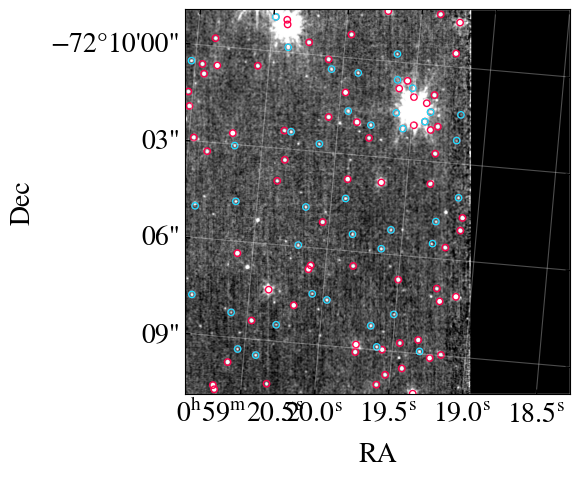

In [68]:
filter = "F115W"
mode = "short"
mosaic_path = f"/net/vdesk/data2/slagter/JWST_NIRCAM_#1227_level_3/mosaic_{filter}_{mode}_exposure.fits"


completeness_lim = 24.8
source_coordinates = SkyCoord(
    ra=world_coord_sources[filter][mode][0] * u.deg,
    dec=world_coord_sources[filter][mode][1] * u.deg,
)

target_wcs, shape_out = PLOT.plot_detection_in_frame(
    Image_path=mosaic_path,
    center=SkyCoord(ra=14.95176547 * u.deg, dec=-72.21625529 * u.deg, frame="icrs"),
    dra=-2.2 * u.arcmin,  # shift east / north
    ddec=2.9 * u.arcmin,
    rot=5 * u.deg,  # rotation of the view (0 = north up)
    width=0.2 * u.arcmin,  # field of view
    height=0.2 * u.arcmin,
    pix_scale=0.01 * u.arcsec,
    source_coordinates=source_coordinates,
    save_name=None,
    tag=(magnitudes[filter][mode] > completeness_lim),
)

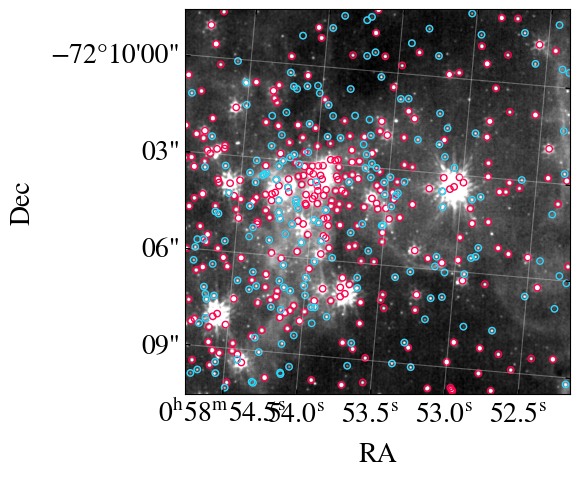

In [ ]:
filter = "F115W"
mode = "long"
mosaic_path = f"/net/vdesk/data2/slagter/JWST_NIRCAM_#1227_level_3/mosaic_{filter}_{mode}_exposure.fits"

completeness_lim = 24.8
source_coordinates = SkyCoord(
    ra=world_coord_sources[filter][mode][0] * u.deg,
    dec=world_coord_sources[filter][mode][1] * u.deg,
)


target_wcs, shape_out = PLOT.plot_detection_in_frame(
    Image_path=mosaic_path,
    center=SkyCoord(ra=14.95176547 * u.deg, dec=-72.21625529 * u.deg, frame="icrs"),
    dra=-4.2 * u.arcmin,  # shift east / north (more - => shift to right)
    ddec=2.9 * u.arcmin,
    rot=5 * u.deg,  # rotation of the view (0 = north up)
    width=0.2 * u.arcmin,  # field of view
    height=0.2 * u.arcmin,
    pix_scale=0.01 * u.arcsec,
    source_coordinates=source_coordinates,
    save_name=None,
    tag=(magnitudes[filter][mode] > completeness_lim),
)

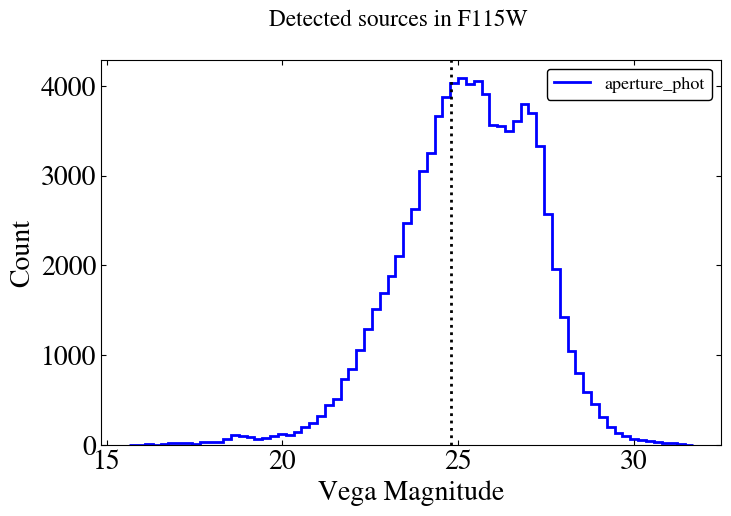

In [32]:
fig = plt.figure()
gs = fig.add_gridspec(1, 1, figure=fig, wspace=0, hspace=0)
ax0 = fig.add_subplot(gs[0, 0])


dx, bin_edges = knuth_bin_width(magnitudes[filter][mode], return_bins=True)

mask = PTK.in_wcs_mask(
    source_coordinates.ra, source_coordinates.dec, target_wcs, shape_out
)

own_hist = np.histogram(magnitudes[filter][mode], bins=bin_edges)[0]
ax0.stairs(
    own_hist,
    edges=bin_edges,
    fill=False,
    label=f"aperture_phot",
    lw=2,
    edgecolor="blue",
)

ax0.legend()
ax0.set_xlabel("Vega Magnitude")
ax0.set_ylabel("Count")
# ax0.set_ylim(0, 500)

ax0.axvline(x=24.8, label="completeness limit", c="black", lw=2, ls=":")
fig.suptitle(f"Detected sources in F115W ")
plt.show()